# مرحله دوم: Data Understanding
## شناخت و بررسی داده‌ها

در این مرحله هدف ما شناخت کامل دیتاست Online Retail است. قبل از هرگونه پاک‌سازی یا تغییر داده، ساختار، کیفیت، ویژگی‌ها و روابط موجود در داده‌ها را بررسی می‌کنیم.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

df = pd.read_excel("Online Retail.xlsx")

print(df.head())

  InvoiceNo StockCode                          Description  Quantity  \
0    536365    85123A   WHITE HANGING HEART T-LIGHT HOLDER         6   
1    536365     71053                  WHITE METAL LANTERN         6   
2    536365    84406B       CREAM CUPID HEARTS COAT HANGER         8   
3    536365    84029G  KNITTED UNION FLAG HOT WATER BOTTLE         6   
4    536365    84029E       RED WOOLLY HOTTIE WHITE HEART.         6   

          InvoiceDate  UnitPrice  CustomerID         Country  
0 2010-12-01 08:26:00       2.55     17850.0  United Kingdom  
1 2010-12-01 08:26:00       3.39     17850.0  United Kingdom  
2 2010-12-01 08:26:00       2.75     17850.0  United Kingdom  
3 2010-12-01 08:26:00       3.39     17850.0  United Kingdom  
4 2010-12-01 08:26:00       3.39     17850.0  United Kingdom  


### **سؤال ۱: دیتاست چند سطر و چند ستون دارد؟**

**هدف از پرسیدن:**

هدف این سؤال شناخت ابعاد دیتاست و مشخص شدن تعداد رکوردها و ویژگی‌های موجود است. این اطلاعات به ما کمک می‌کند حجم داده و میزان اطلاعات در دسترس را بشناسیم.

In [22]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])
print("Dataset shape:", df.shape)

Number of rows: 541909
Number of columns: 8
Dataset shape: (541909, 8)


**تحلیل:**

با اجرای کد، تعداد کل تراکنش‌ها و ستون‌های دیتاست مشخص می‌شود. هر سطر نشان‌دهنده یک ردیف از اطلاعات خرید است. هر ستون نیز یکی از ویژگی‌های مربوط به تراکنش، محصول یا مشتری را نمایش می‌دهد. این اطلاعات دید اولیه‌ای درباره حجم و ساختار داده در اختیار ما قرار می‌دهد.

### **سؤال ۲: نام تمام ستون‌های دیتاست چیست؟**

**هدف از پرسیدن:**

هدف، شناسایی ویژگی‌هایی است که در دیتاست وجود دارند تا بتوانیم نقش هرکدام را در تحلیل رفتار مشتریان مشخص کنیم.

In [24]:
for i, column in enumerate(df.columns):
    print(i + 1, "-", column)

df.head()

1 - InvoiceNo
2 - StockCode
3 - Description
4 - Quantity
5 - InvoiceDate
6 - UnitPrice
7 - CustomerID
8 - Country


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


**تحلیل:**

با مشاهده نام ستون‌ها متوجه می‌شویم دیتاست شامل اطلاعاتی مانند شماره فاکتور، کد محصول، نام محصول، تعداد خرید، تاریخ خرید، قیمت، شناسه مشتری و کشور است. این اطلاعات به ما کمک می‌کنند رفتار خرید مشتریان را از جنبه‌های مختلف بررسی کنیم. ستون `CustomerID` برای شناسایی مشتریان اهمیت زیادی دارد

### **سؤال ۳: نوع داده هر ستون چیست؟**

**هدف از پرسیدن:**

نوع داده مشخص می‌کند هر ستون چه نوع اطلاعاتی را نگهداری می‌کند. این موضوع در انتخاب روش تحلیل و رسم نمودار اهمیت دارد.


In [33]:
print("Column names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)


Column names:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']

Data types:
InvoiceNo              object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[us]
UnitPrice             float64
CustomerID            float64
Country                   str
dtype: object


**تحلیل:**

در خروجی، نوع داده هر ستون مانند عدد صحیح، عدد اعشاری یا متن نمایش داده می‌شود. ستون‌هایی مانند `Quantity` و `UnitPrice` اطلاعات عددی دارند. ستون‌هایی مانند `InvoiceNo` و `Country` اطلاعات شناسه‌ای یا دسته‌ای هستند. ستون `InvoiceDate` نیز باید از نظر نوع داده بررسی شود تا در مرحله تحلیل بتوانیم زمان خریدها را بهتر بررسی کنیم.

##  سؤال 4: تعداد موجودیت‌های یکتا در دیتاست چقدر است؟

### پاسخ
بررسی فایل نشان می‌دهد:

- تعداد فاکتورهای یکتا: 25,900
- تعداد مشتریان دارای شناسه یکتا: 4,372
- تعداد کدهای محصول یکتا: 4,070
- تعداد کشورهای یکتا: 38

### چرا این سؤال را می‌پرسیم؟

چون در پروژه پیش‌بینی ریزش، واحد اصلی تحلیل مشتری است؛ نه ردیف فاکتور. شناخت تعداد مشتریان و فاکتورها مشخص می‌کند با چه حجمی از رفتار مشتریان روبه‌رو هستیم.


In [26]:
print("Unique invoices:", df["InvoiceNo"].nunique())
print("Unique customers:", df["CustomerID"].nunique())
print("Unique products:", df["StockCode"].nunique())
print("Unique countries:", df["Country"].nunique())

Unique invoices: 25900
Unique customers: 4372
Unique products: 4070
Unique countries: 38


# بخش دوم: بررسی کیفیت داده‌ها

### **سؤال 5: در هر ستون چند مقدار Null وجود دارد؟**

**هدف از پرسیدن:**

مقادیر Null نشان‌دهنده اطلاعات ثبت‌نشده هستند. بررسی آن‌ها اهمیت دارد؛ زیرا ممکن است نبود اطلاعات بعضی مشتریان، تحلیل رفتار آن‌ها را دشوار کند.

             Missing_Count  Missing_Percent
CustomerID          135080        24.926694
Description           1454         0.268311
StockCode                0         0.000000
InvoiceNo                0         0.000000
Quantity                 0         0.000000
InvoiceDate              0         0.000000
UnitPrice                0         0.000000
Country                  0         0.000000


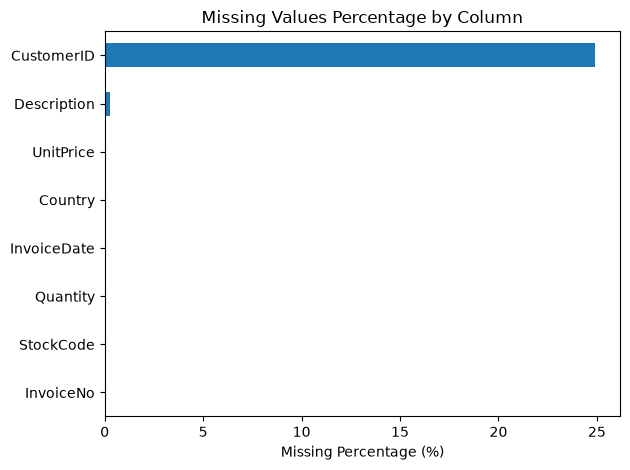

In [34]:
missing_count = df.isna().sum()
missing_percent = df.isna().mean() * 100

missing_report = pd.DataFrame({
    "Missing_Count": missing_count,
    "Missing_Percent": missing_percent
})

print(missing_report.sort_values(
    by="Missing_Percent",
    ascending=False
))

missing_report["Missing_Percent"].sort_values().plot(
    kind="barh",
    title="Missing Values Percentage by Column",
    xlabel="Missing Percentage (%)"
)

plt.tight_layout()
plt.show()

**تحلیل:**

خروجی نشان می‌دهد در هر ستون چند مقدار خالی وجود دارد. وجود مقدار Null در ستون `CustomerID` برای پروژه ما اهمیت زیادی دارد؛ زیرا بدون شناسه مشتری نمی‌توان خریدهای مربوط به یک مشتری را به‌درستی دنبال کرد. در این مرحله فقط مقادیر خالی را شناسایی می‌کنیم و هیچ مقداری را حذف یا جایگزین نمی‌کنیم.

---

### **سؤال 6: درصد داده‌های گمشده در هر ستون چقدر است؟**

**هدف از پرسیدن:**

تعداد مقادیر گمشده به‌تنهایی کافی نیست. درصد آن‌ها کمک می‌کند میزان تأثیر داده‌های ناقص را بهتر ارزیابی کنیم.

In [ ]:
missing_percent = (df.isnull().sum() / len(df)) * 100

print(missing_percent.round(2))

**تحلیل:**

با مشاهده درصد داده‌های گمشده می‌توان تشخیص داد کدام ستون‌ها بیشترین مشکل را دارند. اگر درصد مقادیر گمشده در `CustomerID` زیاد باشد، ممکن است تعداد قابل‌توجهی از تراکنش‌ها برای تحلیل مشتریان قابل استفاده نباشند. این موضوع در مرحله Data Preparation باید مورد توجه قرار گیرد.

### **سؤال 7: آیا در دیتاست رکورد تکراری وجود دارد؟**

**هدف از پرسیدن:**

رکوردهای تکراری ممکن است باعث شوند بعضی اطلاعات بیش از یک بار در تحلیل محاسبه شوند. بنابراین باید تعداد آن‌ها را بررسی کنیم.


In [35]:
print("Number of duplicate records: ")
print(df.duplicated().sum())

Number of duplicate records: 
5268


**تحلیل:**

خروجی مشخص می‌کند چند ردیف کاملاً تکراری در دیتاست وجود دارد. وجود رکوردهای تکراری ممکن است بر محاسبه تعداد تراکنش‌ها و تحلیل رفتار خرید اثر بگذارد. در این مرحله فقط تعداد آن‌ها را بررسی می‌کنیم و هیچ رکوردی را حذف نمی‌کنیم.

### **سؤال 8: چه درصدی از کل داده‌ها تکراری هستند؟**

**هدف از پرسیدن:**

هدف، مشخص کردن میزان تأثیر رکوردهای تکراری نسبت به کل دیتاست است.

In [36]:
duplicate_count = df.duplicated().sum()

duplicate_percent = (duplicate_count / len(df)) * 100

print("Number of duplicated record: ", duplicate_count)
print("Percent of duplicated record: ", round(duplicate_percent, 2), "%")

Number of duplicated record:  5268
Percent of duplicated record:  0.97 %


# بخش سوم: بررسی رفتار خرید و زمان تراکنش‌ها

### **سؤال 9: توزیع خریدها در طول زمان چگونه است؟**

**هدف از پرسیدن:**

تاریخ خرید یکی از مهم‌ترین اطلاعات برای پروژه ریزش مشتریان است. با بررسی زمان تراکنش‌ها می‌توان روند خرید در ماه‌های مختلف را مشاهده کرد.

InvoiceDate
2010-12    42481
2011-01    35147
2011-02    27707
2011-03    36748
2011-04    29916
2011-05    37030
2011-06    36874
2011-07    39518
2011-08    35284
2011-09    50226
2011-10    60742
2011-11    84711
2011-12    25525
Freq: M, Name: count, dtype: int64


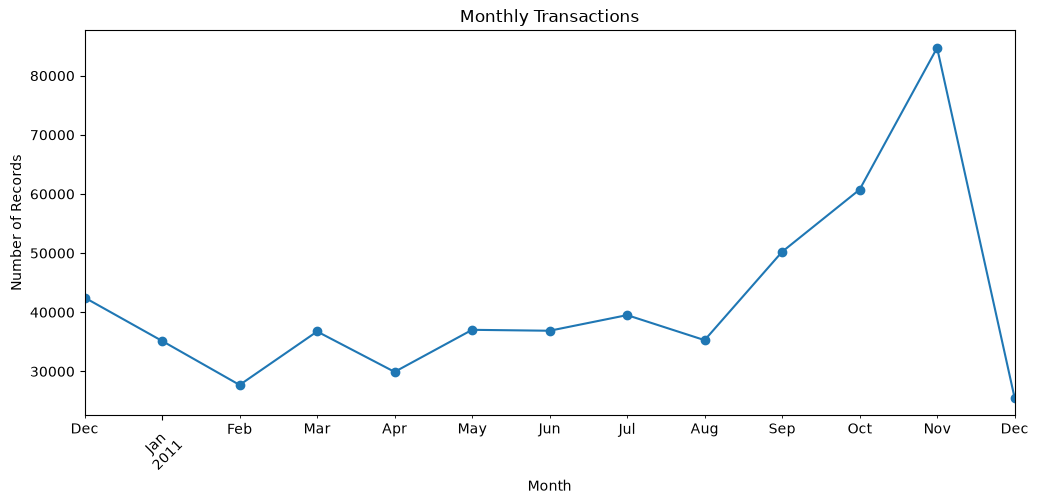

In [2]:
invoice_dates = pd.to_datetime(
    df["InvoiceDate"],
    errors="coerce"
)

monthly_sales = invoice_dates.dt.to_period("M").value_counts().sort_index()

print(monthly_sales)

plt.figure(figsize=(12, 5))

monthly_sales.plot(kind="line", marker="o")

plt.title("Monthly Transactions")
plt.xlabel("Month")
plt.ylabel("Number of Records")
plt.xticks(rotation=45)

plt.show()

**تحلیل:**

نمودار تعداد رکوردهای ثبت‌شده در ماه‌های مختلف را نمایش می‌دهد. با بررسی آن می‌توان ماه‌های پرتراکنش و کم‌تراکنش را شناسایی کرد. این بررسی برای شناخت روند زمانی فعالیت فروشگاه اهمیت دارد. همچنین به ما کمک می‌کند محدوده زمانی مناسب برای تحلیل رفتار مشتریان را بهتر بشناسیم.

---

### **سؤال 10: تعداد خریدها در روزهای مختلف هفته چگونه است؟**

**هدف از پرسیدن:**

هدف بررسی این است که آیا خرید مشتریان در روزهای خاصی از هفته بیشتر اتفاق می‌افتد یا خیر.

InvoiceDate
Thursday     103857
Tuesday      101808
Monday        95111
Wednesday     94565
Friday        82193
Sunday        64375
Name: count, dtype: int64


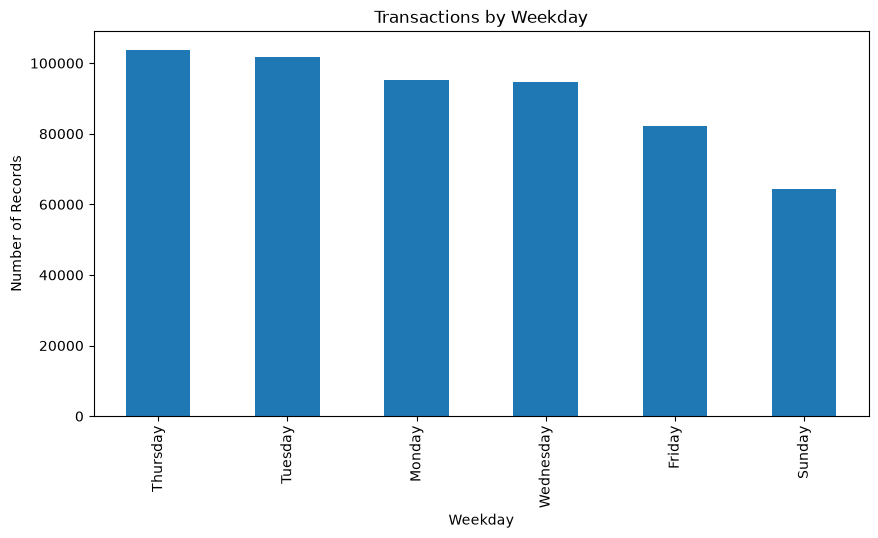

In [3]:
invoice_dates = pd.to_datetime(
    df["InvoiceDate"],
    errors="coerce"
)

weekday_names = invoice_dates.dt.day_name()

weekday_counts = weekday_names.value_counts()

print(weekday_counts)

plt.figure(figsize=(10, 5))

weekday_counts.plot(kind="bar")

plt.title("Transactions by Weekday")
plt.xlabel("Weekday")
plt.ylabel("Number of Records")

plt.show()

**تحلیل:**

این نمودار تعداد رکوردهای خرید را در روزهای مختلف هفته نشان می‌دهد. اگر در بعضی روزها تعداد تراکنش‌ها بیشتر باشد، می‌توان گفت فعالیت خرید در آن روزها بیشتر بوده است. این اطلاعات برای شناخت الگوی زمانی خرید مشتریان مفید است.

## سؤال 11: بازه زمانی دیتاست چیست و فعالیت ثبت‌شده در طول ماه‌ها چگونه تغییر می‌کند؟


داده‌ها از **1 دسامبر 2010، ساعت 08:26** تا **9 دسامبر 2011، ساعت 12:50** را پوشش می‌دهند.

در ستون `InvoiceDate` مقدار نامعتبر یا غیرقابل تبدیل به تاریخ مشاهده نشد.

در بررسی ماهانه، بیشترین تعداد ردیف و فاکتور در نوامبر 2011 ثبت شده است:

- تعداد ردیف‌ها در نوامبر: 84,711
- تعداد فاکتورهای یکتا در نوامبر: 3,462

### هدف از پرسیدن:

برای شناخت پوشش زمانی داده، مشاهده روند فعالیت خرید و بررسی امکان استفاده از اطلاعات گذشته برای پیش‌بینی رفتار آینده مشتریان.


Invalid dates: 0
Earliest date: 2010-12-01 08:26:00
Latest date: 2011-12-09 12:50:00

Monthly Summary:
         Row_Count  Unique_Invoices  Unique_Customers
Month                                                
2010-12      42481             2025               948
2011-01      35147             1476               783
2011-02      27707             1393               798
2011-03      36748             1983              1020
2011-04      29916             1744               899
2011-05      37030             2162              1079
2011-06      36874             2012              1051
2011-07      39518             1927               993
2011-08      35284             1737               980
2011-09      50226             2327              1302
2011-10      60742             2637              1425
2011-11      84711             3462              1711
2011-12      25525             1015               686


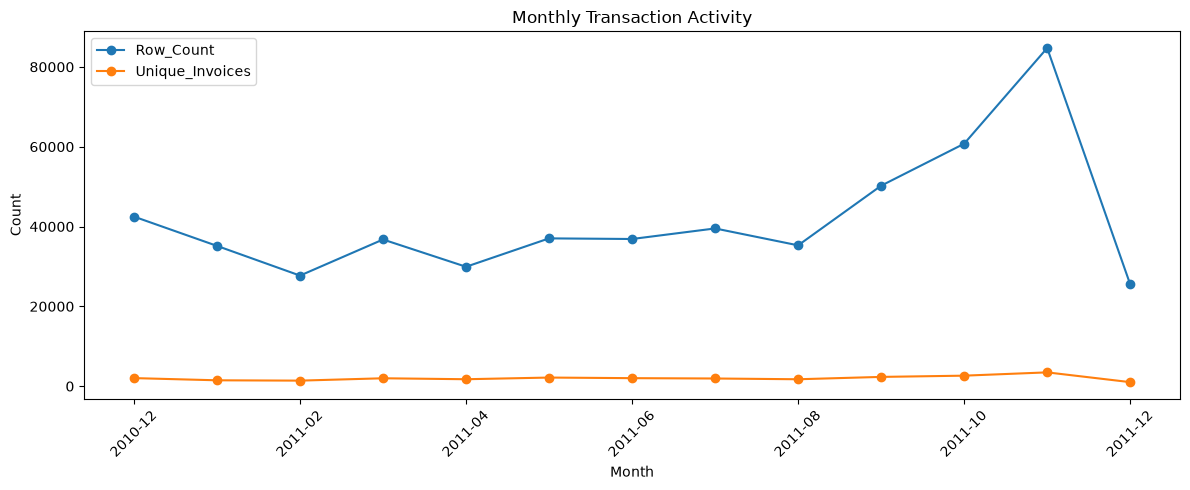

In [4]:
df["InvoiceDate"] = pd.to_datetime(
    df["InvoiceDate"],
    format="%m/%d/%y %H:%M",
    errors="coerce"
)

print("Invalid dates:", df["InvoiceDate"].isna().sum())
print("Earliest date:", df["InvoiceDate"].min())
print("Latest date:", df["InvoiceDate"].max())

monthly_summary = (
    df.dropna(subset=["InvoiceDate"])
    .assign(
        Month=df["InvoiceDate"].dt.to_period("M").astype(str)
    )
    .groupby("Month")
    .agg(
        Row_Count=("InvoiceNo", "size"),
        Unique_Invoices=("InvoiceNo", "nunique"),
        Unique_Customers=("CustomerID", "nunique")
    )
)

print("\nMonthly Summary:")
print(monthly_summary)

monthly_summary[["Row_Count", "Unique_Invoices"]].plot(
    figsize=(12, 5),
    marker="o",
    title="Monthly Transaction Activity"
)

plt.ylabel("Count")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**تحلیل**:

فعالیت ثبت‌شده در برخی ماه‌ها بیشتر از ماه‌های دیگر است. بااین‌حال، تعداد ردیف‌ها و فاکتورها به‌تنهایی نشان‌دهنده تعداد مشتریان فعال یا میزان سود نیست.

دسامبر 2011 فقط تا روز نهم پوشش داده شده است؛ بنابراین نباید آن را با ماه‌های کامل مقایسه کرد، بدون اینکه ناقص‌بودن این بازه در نظر گرفته شود.

### **سؤال 12: کدام کشورها بیشترین تعداد فاکتور خرید را دارند؟**

**هدف از پرسیدن:**

با این سؤال می‌خواهیم کشورهایی را شناسایی کنیم که بیشترین فعالیت خرید در آن‌ها ثبت شده است.


Country
United Kingdom    23494
Germany             603
France              461
EIRE                360
Belgium             119
Spain               105
Netherlands         101
Switzerland          74
Portugal             71
Australia            69
Name: InvoiceNo, dtype: int64


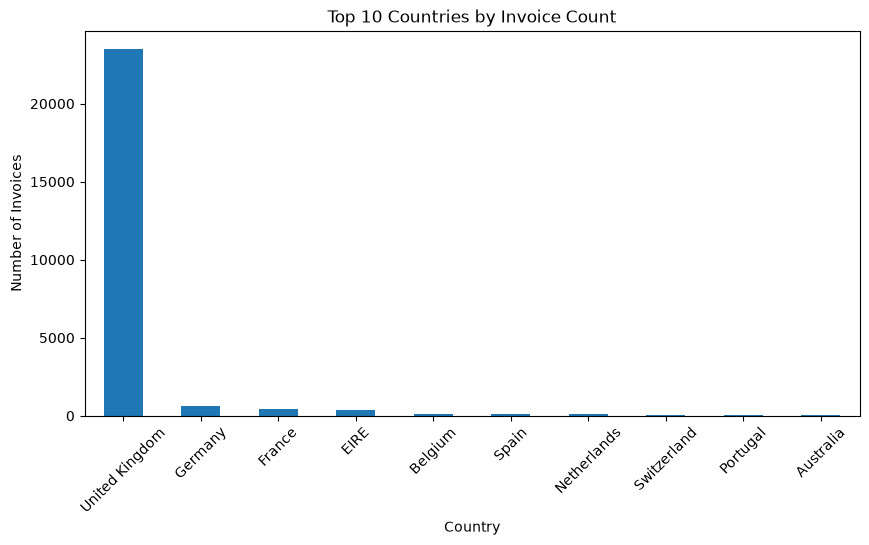

In [5]:
country_invoices = (
    df.groupby("Country")["InvoiceNo"]
    .nunique()
    .sort_values(ascending=False)
)

print(country_invoices.head(10))

country_invoices.head(10).plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Top 10 Countries by Invoice Count")
plt.xlabel("Country")
plt.ylabel("Number of Invoices")
plt.xticks(rotation=45)

plt.show()

**تحلیل:**

این جدول تعداد فاکتورهای منحصربه‌فرد هر کشور را نشان می‌دهد. کشورهایی که فاکتور بیشتری دارند، از نظر تعداد سفارش فعالیت بیشتری در فروشگاه داشته‌اند. این موضوع می‌تواند به شناخت بازارهای مهم کمک کند؛ اما تعداد فاکتور به‌تنهایی نشان‌دهنده وفاداری مشتریان نیست.

---

# بخش چهارم: تحلیل ویژگی‌های عددی

در دیتاست ما دو ویژگی عددی اصلی برای بررسی مقدار و قیمت خرید وجود دارد:

- `Quantity`
- `UnitPrice`

ستون‌های شناسه مانند `CustomerID` را نباید به‌عنوان ویژگی عددی واقعی در تحلیل آماری در نظر بگیریم.

### **سؤال 13: آمار توصیفی ویژگی‌های عددی را استخراج کنید.**

**هدف از پرسیدن:**

آمار توصیفی اطلاعاتی مانند میانگین، کمینه، بیشینه و چارک‌ها را نمایش می‌دهد. این اطلاعات به شناخت اولیه رفتار داده‌های عددی کمک می‌کنند.


In [6]:
numeric_columns = ["Quantity", "UnitPrice"]

df[numeric_columns].describe()

,Quantity,UnitPrice
count,541909.000000,541909.000000
mean,9.552250,4.611114
std,218.081158,96.759853
min,-80995.000000,-11062.060000
25%,1.000000,1.250000
50%,3.000000,2.080000
75%,10.000000,4.130000
max,80995.000000,38970.000000


**تحلیل:**

با بررسی خروجی می‌توان محدوده تغییرات تعداد و قیمت محصولات را مشاهده کرد. مقدار میانگین و میانه به شناخت مقدار معمول خرید کمک می‌کنند. اختلاف زیاد بین کمینه و بیشینه ممکن است نشان‌دهنده وجود مقادیر غیرعادی باشد. این موارد در مرحله آماده‌سازی داده باید دقیق‌تر بررسی شوند.

---

### **سؤال 14: میانگین، میانه و مد ویژگی‌های عددی را محاسبه کنید.**

**هدف از پرسیدن:**

میانگین، میانه و مد سه شاخص مهم آماری هستند که مقدار مرکزی و پرتکرار داده‌ها را نشان می‌دهند.


In [7]:
numeric_columns = ["Quantity", "UnitPrice"]

summary = pd.DataFrame({
    "Mean": df[numeric_columns].mean(),
    "Median": df[numeric_columns].median(),
    "Mode": df[numeric_columns].mode().iloc[0]
})

print(summary)

               Mean  Median  Mode
Quantity   9.552250    3.00  1.00
UnitPrice  4.611114    2.08  1.25


**تحلیل:**

با مقایسه میانگین و میانه می‌توان درباره شکل توزیع داده‌ها اطلاعات اولیه به دست آورد. اگر اختلاف زیادی بین این دو وجود داشته باشد، ممکن است توزیع داده دارای چولگی باشد یا مقادیر بسیار بزرگ و کوچک بر میانگین اثر گذاشته باشند. مد نیز پرتکرارترین مقدار هر ویژگی را مشخص می‌کند.

---

### **سؤال 15: واریانس و انحراف معیار ویژگی‌های عددی را محاسبه کنید.**

**هدف از پرسیدن:**

واریانس و انحراف معیار میزان پراکندگی مقادیر را نسبت به میانگین نشان می‌دهند. این شاخص‌ها به ما کمک می‌کنند میزان تغییرات تعداد و قیمت خرید را بررسی کنیم.


In [8]:
numeric_columns = ["Quantity", "UnitPrice"]

variance = df[numeric_columns].var()
std = df[numeric_columns].std()

print("واریانس:")
print(variance)

print("\nانحراف معیار:")
print(std)

واریانس:
Quantity     47559.391409
UnitPrice     9362.469164
dtype: float64

انحراف معیار:
Quantity     218.081158
UnitPrice     96.759853
dtype: float64


**تحلیل:**

انحراف معیار بیشتر نشان‌دهنده پراکندگی بیشتر مقادیر است. اگر انحراف معیار تعداد خرید زیاد باشد، یعنی مقدار محصولات در فاکتورها تفاوت زیادی دارد. در مورد قیمت نیز پراکندگی زیاد می‌تواند نشان‌دهنده تفاوت قیمت محصولات مختلف باشد.

---

### **سؤال 16: برای ویژگی‌های عددی Histogram رسم کنید.**
### **سؤال 17: برای ویژگی‌های عددی Boxplot رسم کنید.**

**هدف از پرسیدن:**

نمودار Boxplot برای بررسی پراکندگی داده‌ها و شناسایی مقادیر پرت استفاده می‌شود.


**هدف از پرسیدن:**

هیستوگرام شکل توزیع مقادیر را نمایش می‌دهد و به شناسایی تمرکز داده‌ها و مقادیر غیرمعمول کمک می‌کند.


            Quantity      UnitPrice
count  541909.000000  541909.000000
mean        9.552250       4.611114
std       218.081158      96.759853
min    -80995.000000  -11062.060000
25%         1.000000       1.250000
50%         3.000000       2.080000
75%        10.000000       4.130000
max     80995.000000   38970.000000

Selected percentiles:
       Quantity  UnitPrice
0.500      3.00     2.0800
0.750     10.00     4.1300
0.900     24.00     7.9500
0.950     29.00     9.9500
0.990    100.00    18.0000
0.999    468.92   205.5598


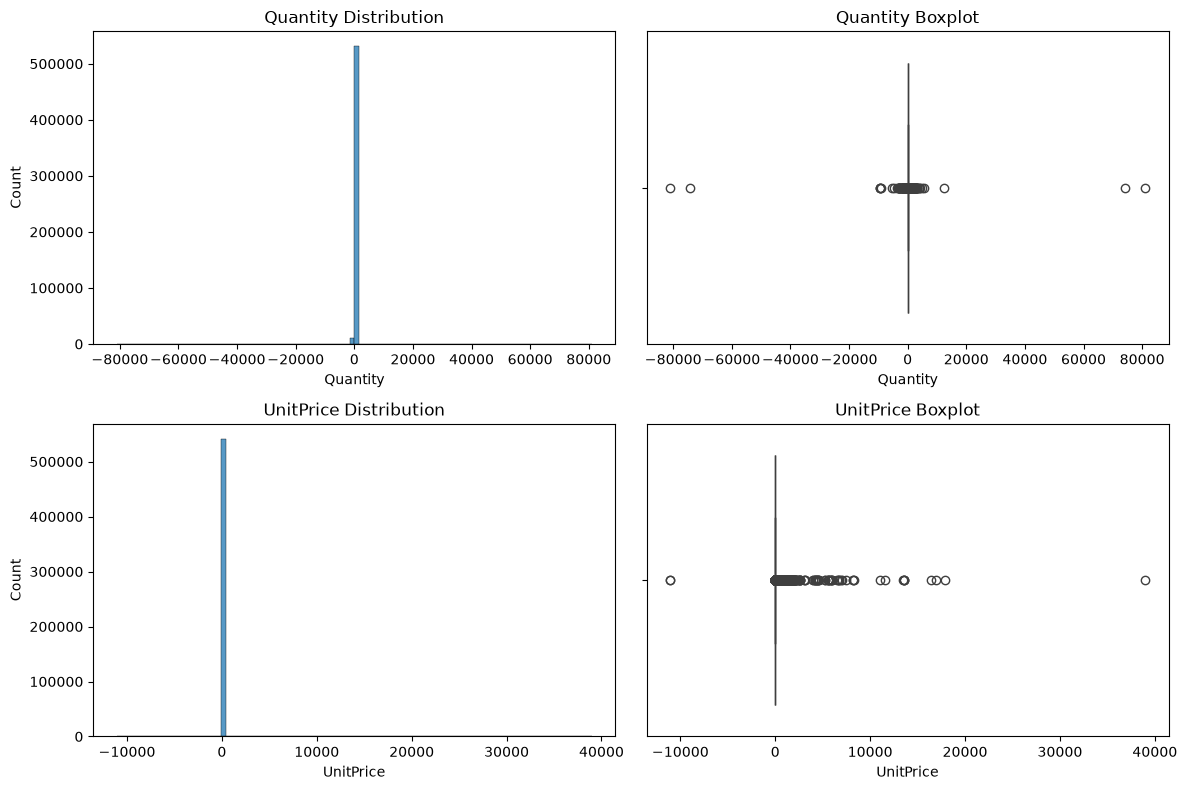

In [9]:
file_path = Path("Online Retail.xlsx")

if not file_path.exists():
    file_path = Path("Online Retail.xlsx")

df = pd.read_excel(file_path)
import pandas as pd
df = pd.read_excel("Online Retail.xlsx")
print(df[["Quantity", "UnitPrice"]].describe())

print("\nSelected percentiles:")
print(
    df[["Quantity", "UnitPrice"]].quantile(
        [0.50, 0.75, 0.90, 0.95, 0.99, 0.999]
    )
)

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

sns.histplot(df["Quantity"], bins=100, ax=axes[0, 0])
axes[0, 0].set_title("Quantity Distribution")

sns.boxplot(x=df["Quantity"], ax=axes[0, 1])
axes[0, 1].set_title("Quantity Boxplot")

sns.histplot(df["UnitPrice"], bins=100, ax=axes[1, 0])
axes[1, 0].set_title("UnitPrice Distribution")

sns.boxplot(x=df["UnitPrice"], ax=axes[1, 1])
axes[1, 1].set_title("UnitPrice Boxplot")

plt.tight_layout()
plt.show()

**تحلیل:**

با مشاهده نمودار می‌توان فهمید بیشتر تراکنش‌ها در چه محدوده‌ای از تعداد و قیمت قرار دارند. اگر بخش بزرگی از داده‌ها در یک محدوده متمرکز باشد، توزیع نامتقارن یا چوله باشد، باید این موضوع را در تحلیل‌های بعدی در نظر بگیریم. مقادیر بسیار دور از بخش اصلی نمودار نیز نیازمند بررسی بیشتر هستند.

---

### **سؤال 17: برای ویژگی‌های عددی Boxplot رسم کنید.**

**هدف از پرسیدن:**

نمودار Boxplot برای بررسی پراکندگی داده‌ها و شناسایی مقادیر پرت استفاده می‌شود.


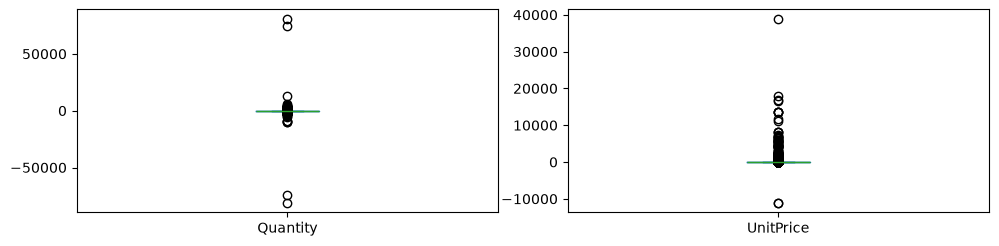

In [10]:
import matplotlib.pyplot as plt


df[numeric_columns].plot(
    kind="box",
    subplots=True,
    layout=(5,3),
    figsize=(15,12)
)

plt.tight_layout()
plt.show()

**تحلیل:**

در نمودار Boxplot می‌توان محدوده اصلی داده‌ها و مقادیر دورافتاده را مشاهده کرد. وجود نقاط خارج از محدوده نمودار می‌تواند نشان‌دهنده مقادیر پرت باشد. در فروشگاه آنلاین، بعضی خریدهای عمده ممکن است تعداد بسیار زیادی محصول داشته باشند؛ بنابراین هر مقدار پرت الزاماً اشتباه نیست.

---

### **سؤال 18: برای ویژگی‌های عددی KDE Plot رسم کنید.**

**هدف از پرسیدن:**

نمودار KDE شکل کلی توزیع داده‌ها را به‌صورت یک منحنی پیوسته نمایش می‌دهد.


In [ ]:
import matplotlib.pyplot as plt

numeric_columns = df.select_dtypes(include=["int64", "float64"]).columns

for column in numeric_columns:

    plt.figure(figsize=(6,4))

    df[column].plot(
        kind="kde"
    )

    plt.title(f"KDE Plot - {column}")

    plt.xlabel(column)

    plt.ylabel("Density")

    plt.show()

**تحلیل:**

نمودار KDE نشان می‌دهد مقادیر هر ویژگی بیشتر در چه محدوده‌ای متمرکز شده‌اند. قله‌های نمودار محدوده‌هایی را نشان می‌دهند که تراکم داده در آن‌ها بیشتر است. این نمودار در کنار هیستوگرام به شناخت بهتر توزیع تعداد و قیمت خرید کمک می‌کند.

---

# بخش پنجم: تحلیل ویژگی‌های دسته‌ای

### **سؤال 19: فراوانی ویژگی‌های دسته‌ای را محاسبه کنید.**

**هدف از پرسیدن:**

هدف این سؤال بررسی تعداد تکرار هر مقدار در ستون‌های دسته‌ای است. این کار به شناخت محصولات و کشورهایی که بیشترین حضور را در دیتاست دارند کمک می‌کند.


In [11]:
categorical_columns = [
    "Description",
    "Country",
    
]

for column in categorical_columns:

    print(f"\n===== {column} =====")

    print(df[column].value_counts())

for column in categorical_columns:

    print(f"\n===== {column} =====")

    print(df[column].value_counts(normalize=True) * 100)


===== Description =====
Description
WHITE HANGING HEART T-LIGHT HOLDER    2369
REGENCY CAKESTAND 3 TIER              2200
JUMBO BAG RED RETROSPOT               2159
PARTY BUNTING                         1727
LUNCH BAG RED RETROSPOT               1638
                                      ... 
LETTER "U" BLING KEY RING                1
wet                                      1
wet boxes                                1
????damages????                          1
lost                                     1
Name: count, Length: 4223, dtype: int64

===== Country =====
Country
United Kingdom          495478
Germany                   9495
France                    8557
EIRE                      8196
Spain                     2533
Netherlands               2371
Belgium                   2069
Switzerland               2002
Portugal                  1519
Australia                 1259
Norway                    1086
Italy                      803
Channel Islands            758
Finland           

**تحلیل:**

با بررسی فراوانی کشورها مشخص می‌شود بیشترین تراکنش‌ها مربوط به کدام کشورها هستند. همچنین با بررسی محصولات پرتکرار می‌توان محصولات پر تکرار در فاکتورها را شناسایی کرد. این اطلاعات برای شناخت بازار و الگوهای خرید مفید هستند.

---

### **سؤال 20: برای ویژگی‌های دسته‌ای Countplot رسم کنید.**

**هدف از پرسیدن:**

Countplot تعداد تکرار هر دسته را به‌صورت نمودار میله‌ای نمایش می‌دهد و مقایسه گروه‌ها را آسان‌تر می‌کند.


In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

for column in categorical_columns:

    plt.figure(figsize=(6,4))

    sns.countplot(
        data=df,
        x=column
    )

    plt.title(f"Countplot - {column}")

    plt.show()

**تحلیل:**

این نمودار ده کشور دارای بیشترین تعداد رکورد را نمایش می‌دهد. از روی آن می‌توان متوجه شد کدام کشورها سهم بیشتری از تراکنش‌های ثبت‌شده دارند. البته تعداد رکوردها الزاماً برابر با تعداد مشتریان منحصربه‌فرد نیست؛ بنابراین نباید آن را مستقیماً تعداد مشتریان هر کشور در نظر گرفت.

---

### **سؤال 21: توزیع مشتریان در کشورهای مختلف چگونه است؟**

**هدف از پرسیدن:**

در پروژه ما بررسی کشور مشتریان جایگزین بررسی جنسیت بیماران در سناریوی اصلی شده است. هدف، شناخت پراکندگی مشتریان در کشورهای مختلف است.


In [ ]:
country_customers = (
    df.groupby("Country")["CustomerID"]
    .nunique()
    .sort_values(ascending=False)
)

print(country_customers.head(15))

**تحلیل:**

این جدول تعداد مشتریان منحصربه‌فرد هر کشور را نشان می‌دهد. با استفاده از آن می‌توان کشورهایی را که بیشترین تعداد مشتری را دارند شناسایی کرد. این اطلاعات به شناخت بازارهای اصلی فروشگاه کمک می‌کند و در تحلیل‌های بعدی می‌توان رفتار مشتریان کشورهای مختلف را با هم مقایسه کرد.

---

# بخش ششم: بررسی ارتباط ویژگی‌ها با رفتار خرید

در دیتاست ما ستون Target آماده وجود ندارد؛ بنابراین نمی‌توانیم مانند دیتاست بیماری قلبی، ویژگی‌ها را بر اساس دو کلاس Target مقایسه کنیم. در عوض، روابط میان ویژگی‌های موجود را بررسی می‌کنیم.

### **سؤال ۲۲: رابطه تعداد خرید و قیمت محصول چگونه است؟**

**هدف از پرسیدن:**

هدف بررسی ارتباط بین تعداد محصول خریداری‌شده و قیمت هر واحد محصول است.


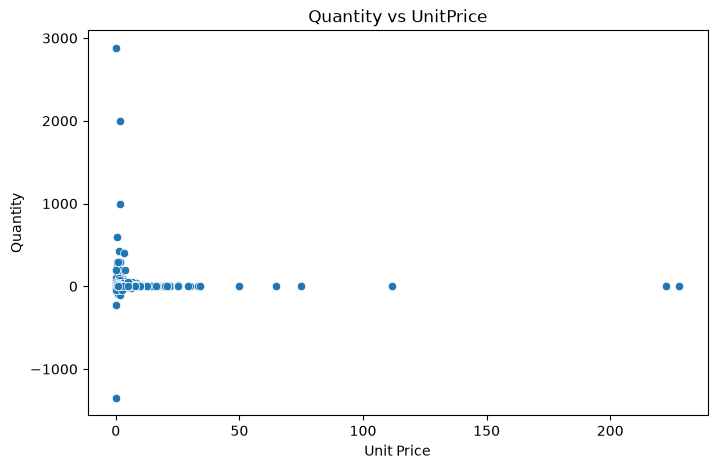

In [15]:
plt.figure(figsize=(8, 5))

sample_data = df.sample(
    n=min(3000, len(df)),
    random_state=42
)

sns.scatterplot(
    data=sample_data,
    x="UnitPrice",
    y="Quantity"
)

plt.title("Quantity vs UnitPrice")
plt.xlabel("Unit Price")
plt.ylabel("Quantity")

plt.show()

**تحلیل:**

نمودار پراکندگی ارتباط میان تعداد و قیمت محصولات را نمایش می‌دهد. با مشاهده نقاط می‌توان فهمید آیا خرید تعداد زیاد بیشتر در محصولات ارزان اتفاق می‌افتد یا خیر. وجود نقاط دورافتاده نیز نشان‌دهنده تراکنش‌هایی با تعداد یا قیمت غیرمعمول است.

---


### **سؤال 23: آیا محصولات مختلف از نظر تعداد فروش تفاوت دارند؟**

**هدف از پرسیدن:**

هدف شناسایی محصولاتی است که بیشترین تعداد فروش ثبت‌شده را دارند و بررسی میزان تفاوت محبوبیت محصولات است.


In [ ]:
top_products = (
    df.groupby("Description")["Quantity"]
    .sum()
    .sort_values(ascending=False)
)

print(top_products.head(10))

top_products.head(10).plot(
    kind="bar",
    figsize=(12, 5)
)

plt.title("Top 10 Products by Quantity")
plt.xlabel("Product")
plt.ylabel("Total Quantity")
plt.xticks(rotation=45)

plt.show()

**تحلیل:**

این نمودار ده محصول با بیشترین مجموع تعداد ثبت‌شده را نشان می‌دهد. با بررسی آن می‌توان محصولات پرتکرار و پرفروش از نظر تعداد را شناسایی کرد. البته این معیار به‌تنهایی سودآوری محصول را نشان نمی‌دهد؛ زیرا قیمت محصولات با یکدیگر متفاوت است.

---


# بخش هفتم: تحلیل چندمتغیره و الگوهای مشتریان

### **سؤال 24: مشتریان را از نظر تعداد فاکتورهای ثبت‌شده بررسی کنید.**

**هدف از پرسیدن:**

در پروژه ریزش مشتریان، تعداد دفعات خرید اهمیت زیادی دارد. در این مرحله فقط توزیع تعداد فاکتورهای مشتریان را به‌صورت اکتشافی بررسی می‌کنیم و هنوز ویژگی جدیدی به دیتاست اضافه نمی‌کنیم.


count    4372.000000
mean        5.075480
std         9.338754
min         1.000000
25%         1.000000
50%         3.000000
75%         5.000000
max       248.000000
Name: InvoiceNo, dtype: float64


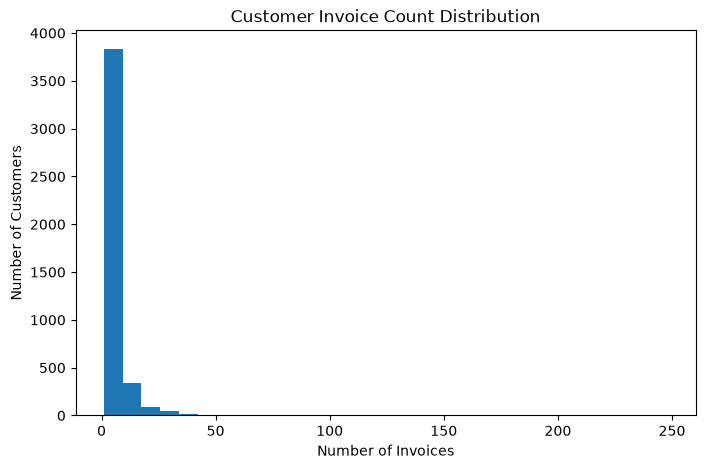

In [16]:
customer_invoice_counts = (
    df.groupby("CustomerID")["InvoiceNo"]
    .nunique()
)

print(customer_invoice_counts.describe())

plt.figure(figsize=(8, 5))

plt.hist(
    customer_invoice_counts,
    bins=30
)

plt.title("Customer Invoice Count Distribution")
plt.xlabel("Number of Invoices")
plt.ylabel("Number of Customers")

plt.show()

**تحلیل:**

این خروجی نشان می‌دهد تعداد فاکتورهای مشتریان چه پراکندگی‌ای دارد. ممکن است تعداد زیادی از مشتریان خریدهای کمی داشته باشند و گروه کوچک‌تری خریدهای بیشتری ثبت کرده باشند. این تفاوت‌ها برای شناسایی الگوهای رفتاری مشتریان در مراحل بعدی اهمیت دارند.

---


### **سؤال 25: مشتریان را از نظر آخرین زمان خرید بررسی کنید.**

**هدف از پرسیدن:**

فاصله زمانی از آخرین خرید یکی از اطلاعات مهم در تحلیل ریزش مشتریان است. مشتریانی که مدت زیادی از آخرین خریدشان گذشته است، ممکن است در معرض خطر غیرفعال شدن باشند.


In [ ]:
invoice_dates = pd.to_datetime(
    df["InvoiceDate"],
    errors="coerce"
)

date_data = pd.DataFrame({
    "CustomerID": df["CustomerID"],
    "InvoiceDate": invoice_dates
})

last_purchase = (
    date_data.dropna(subset=["CustomerID", "InvoiceDate"])
    .groupby("CustomerID")["InvoiceDate"]
    .max()
)

print(last_purchase.head(10))
plt.figure(figsize=(10, 5))

last_purchase.hist(bins=30)

plt.title("Last Purchase Date Distribution")
plt.xlabel("Last Purchase Date")
plt.ylabel("Number of Customers")

plt.show()

**تحلیل:**

این خروجی آخرین تاریخ ثبت‌شده خرید هر مشتری را نمایش می‌دهد. با بررسی تاریخ‌ها می‌توان مشتریانی را که آخرین خریدشان در ابتدای دوره ثبت شده است از مشتریانی که در انتهای دوره خرید داشته‌اند تشخیص داد. این بررسی برای مرحله بعد مهم است؛ زیرا زمان آخرین خرید یکی از اطلاعات اصلی در تحلیل احتمال ریزش مشتری است.

---

### **سؤال 26: چه الگوهای اولیه‌ای در رفتار مشتریان مشاهده می‌شود؟**

**هدف از پرسیدن:**

هدف جمع‌بندی مشاهدات مرحله Data Understanding و شناسایی تفاوت‌های اولیه میان مشتریان است.

**پاسخ و تحلیل:**

با بررسی تعداد فاکتورهای مشتریان می‌توان تفاوت میان مشتریان کم‌خرید و پرخرید را مشاهده کرد. همچنین تاریخ آخرین خرید اطلاعاتی درباره میزان تازگی فعالیت مشتریان ارائه می‌دهد. برخی مشتریان ممکن است خریدهای مکرر داشته باشند، در حالی که برخی دیگر فقط یک یا چند بار خرید کرده باشند.

در این مرحله هنوز مشتریان را به‌صورت رسمی خوشه‌بندی نمی‌کنیم و برچسب ریزش نیز تولید نمی‌کنیم. این کار در مراحل بعدی پروژه انجام خواهد شد.

---

## سؤال 27: چه محدودیت‌هایی ممکن است بر تحلیل و پیش‌بینی ریزش مشتری اثر بگذارند؟


مهم‌ترین محدودیت‌های مشاهده‌شده عبارت‌اند از:

1. حدود 24.93 درصد ردیف‌ها فاقد CustomerID هستند.
2. تعداد 5,268 ردیف تکراری کامل وجود دارد.
3. برخی ردیف‌ها مربوط به لغو فاکتور هستند.
4. در Quantity مقادیر منفی و بسیار بزرگ مشاهده می‌شود.
5. در UnitPrice مقادیر صفر، منفی و بسیار بزرگ وجود دارد.
6. بازه زمانی داده‌ها تقریباً یک سال است و ماه دسامبر 2011 ناقص است.
7. حدود 91.43 درصد ردیف‌ها مربوط به بریتانیاست.
8. برچسب آماده‌ای برای ریزش مشتری وجود ندارد.
9. اطلاعات مستقیمی درباره علت ترک مشتری، هزینه کمپین بازگشت یا نتیجه تماس با مشتری در دیتاست ثبت نشده است.

### هدف از پرسیدن:

برای جمع‌بندی کیفیت، محدودیت‌ها و قابلیت استفاده از داده در پروژه و تعیین مسائلی که باید در مراحل بعدی مورد توجه قرار بگیرند.


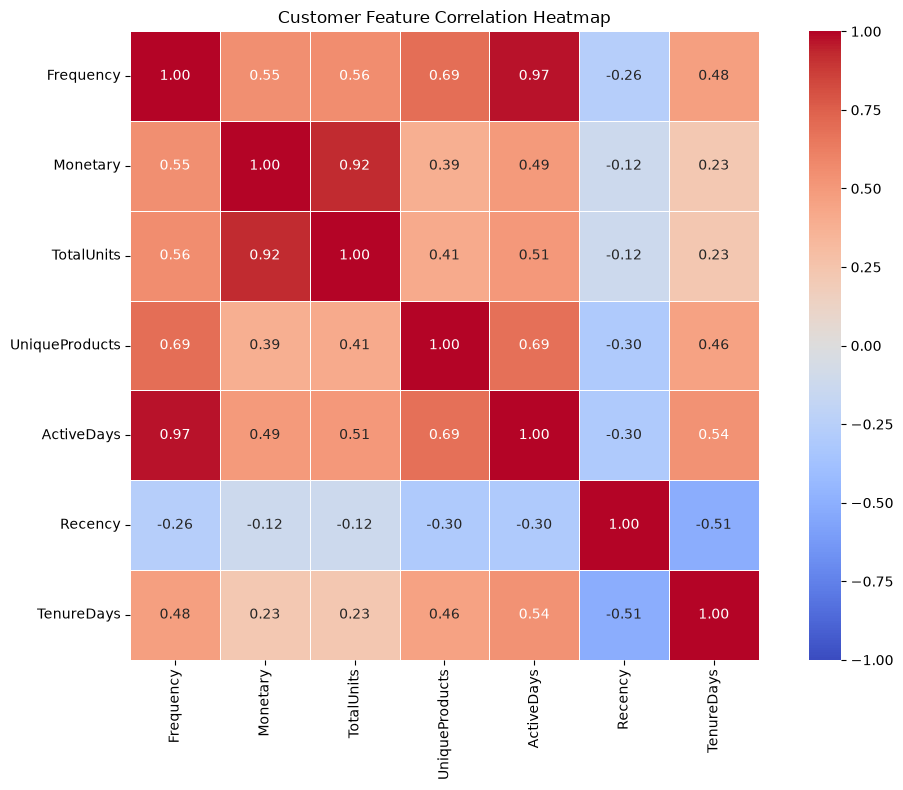

In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


df_corr = df.copy()

df_corr["InvoiceDate"] = pd.to_datetime(
    df_corr["InvoiceDate"],
    format="%m/%d/%y %H:%M",
    errors="coerce"
)

df_corr["Quantity"] = pd.to_numeric(
    df_corr["Quantity"], errors="coerce"
)
df_corr["UnitPrice"] = pd.to_numeric(
    df_corr["UnitPrice"], errors="coerce"
)

cancelled = df_corr["InvoiceNo"].astype("string").str.startswith(
    "C", na=False
)

valid = (
    (~cancelled)
    & (df_corr["Quantity"] > 0)
    & (df_corr["UnitPrice"] > 0)
    & df_corr["InvoiceDate"].notna()
    & df_corr["CustomerID"].notna()
)

sales = df_corr.loc[valid].copy()

# مبلغ هر ردیف خرید
sales["LineTotal"] = sales["Quantity"] * sales["UnitPrice"]

# ساخت ویژگی‌ها در سطح مشتری
customer_features = sales.groupby("CustomerID").agg(
    Frequency=("InvoiceNo", "nunique"),
    Monetary=("LineTotal", "sum"),
    TotalUnits=("Quantity", "sum"),
    UniqueProducts=("StockCode", "nunique"),
    ActiveDays=("InvoiceDate", lambda x: x.dt.date.nunique()),
    FirstPurchase=("InvoiceDate", "min"),
    LastPurchase=("InvoiceDate", "max")
)

# تاریخ مرجع برای محاسبه فاصله از آخرین خرید
reference_date = sales["InvoiceDate"].max() + pd.Timedelta(days=1)

customer_features["Recency"] = (
    reference_date - customer_features["LastPurchase"]
).dt.days

customer_features["TenureDays"] = (
    customer_features["LastPurchase"]
    - customer_features["FirstPurchase"]
).dt.days

# انتخاب ویژگی‌های عددی معنادار؛ شناسه‌ها و تاریخ‌ها حذف می‌شوند
features = [
    "Frequency",
    "Monetary",
    "TotalUnits",
    "UniqueProducts",
    "ActiveDays",
    "Recency",
    "TenureDays"
]

corr = customer_features[features].corr(method="pearson")

# رسم هیت‌مپ
plt.figure(figsize=(11, 8))

sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    linewidths=0.5
)

plt.title("Customer Feature Correlation Heatmap")
plt.tight_layout()
plt.show()


### تحلیل 

دیتاست برای بررسی مقدماتی الگوی خرید و ساخت یک مسئله پیش‌بینی ریزش قابل استفاده است؛ اما پیش از مدل‌سازی باید تعریف ریزش، خرید معتبر و نحوه برخورد با تراکنش‌های لغوشده مشخص شود.

همچنین نمی‌توان صرفاً از این دیتاست نتیجه گرفت که یک کمپین بازگشت مشتری واقعاً مؤثر است؛ برای سنجش اثربخشی کمپین به اطلاعات مربوط به هزینه‌ها و نتایج اقدام‌های بازاریابی یا آزمایش کنترل‌شده نیاز داریم.